# 18 — Regional Baseline Modeling V2
## Support-Only Locked Region (Notebook 17 V2)

## Purpose

Notebook 17 V2 has now locked the main experimental domain using **training-period
support only**. The selected region is no longer chosen using Emerging-3 counts,
August labels, or September labels.

This notebook establishes the baseline on **whatever region is currently locked by
Notebook 17 V2**. It intentionally reads Notebook 17's methodology metadata instead
of hard-coding the old T1 / current-node domain.

The main questions are:

1. How strong is simple next-day persistence on the newly locked regional domain?
2. How strong is Logistic Regression using only local fire history?
3. Does same-cell ERA5 weather add predictive information?
4. Does using current-day fire information improve an end-of-day `t` → `t+1`
   baseline?
5. How do the models behave in **Emerging-3** versus persistent contexts?

---

## Forecast protocol

Two timing regimes are kept explicit.

### Legacy-parity regime

```text
fire history: t-1 or earlier
weather:      day t
label:        FIRMS-detected hotspot at t+1
```

This preserves continuity with earlier experiments.

### End-of-day aligned regime

If the forecast is issued **after day t is complete**, current-day FIRMS activity is
also available:

```text
current fire: t
fire history: t-1 or earlier
weather:      day t
label:        FIRMS-detected hotspot at t+1
```

ERA5 is reanalysis here, so this remains a retrospective forecasting experiment,
not yet a live operational system.

---

## Evaluation discipline

- Train: May–July 2026
- Validation: August 2026
- Final test: September 2026 remains **SEALED**
- Region: read from Notebook 17 V2 metadata
- Node count: read dynamically from the current dataset / metadata

No September score, subgroup count, probability, or error analysis is displayed here.

In [2]:
# 1. Imports
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    brier_score_loss,
    precision_recall_curve,
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 160)
pd.set_option("display.width", 220)

RANDOM_STATE = 42
RUN_TEST = False

In [3]:
# 2. Resolve project paths + Notebook 17 V2 provenance

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate "
        "data/processed/regional_025/karhut_ml_dataset_regional_025.csv. "
        "Run Notebook 17 V2 first or set PROJECT_ROOT manually."
    )


DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

NB17_EXPORT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_dataset"
    / "exports"
)

METHODOLOGY_PATH = (
    NB17_EXPORT_DIR
    / "regional_025_methodology_metadata.json"
)

LOCK_PATH = (
    NB17_EXPORT_DIR
    / "regional_domain_lock_train_only.json"
)

if not METHODOLOGY_PATH.exists():
    raise FileNotFoundError(
        "Notebook 17 V2 methodology metadata was not found:\n"
        f"{METHODOLOGY_PATH}\n\n"
        "Run Notebook 17 V2 through its export cells before Notebook 18 V2."
    )

if not LOCK_PATH.exists():
    raise FileNotFoundError(
        "Notebook 17 V2 regional lock metadata was not found:\n"
        f"{LOCK_PATH}"
    )


methodology_metadata = json.loads(
    METHODOLOGY_PATH.read_text(
        encoding="utf-8"
    )
)

lock_metadata = json.loads(
    LOCK_PATH.read_text(
        encoding="utf-8"
    )
)


LOCKED_REGION_ID = str(
    lock_metadata["candidate_id"]
)

LOCKED_BBOX = (
    float(lock_metadata["bbox_wgs84"]["west"]),
    float(lock_metadata["bbox_wgs84"]["south"]),
    float(lock_metadata["bbox_wgs84"]["east"]),
    float(lock_metadata["bbox_wgs84"]["north"]),
)

EXPECTED_NODES_FROM_METADATA = int(
    methodology_metadata[
        "weather"
    ][
        "requested_grid_centers"
    ]
)


# Do not overwrite the previous T1 baseline result folder.
RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_baseline_v2_support_only"
    / LOCKED_REGION_ID.lower()
)

FIGURES_DIR = (
    RESULTS_DIR
    / "figures"
)

MODELS_DIR = (
    RESULTS_DIR
    / "models"
)

for p in [
    RESULTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )


print("PROJECT_ROOT             :", PROJECT_ROOT)
print("DATA_PATH                :", DATA_PATH)
print("Notebook 17 lock         :", LOCKED_REGION_ID)
print("Locked bbox              :", LOCKED_BBOX)
print("Expected nodes (metadata):", EXPECTED_NODES_FROM_METADATA)
print("RESULTS_DIR              :", RESULTS_DIR)

PROJECT_ROOT             : c:\Users\Asus\Documents\skripsi-karhut
DATA_PATH                : c:\Users\Asus\Documents\skripsi-karhut\data\processed\regional_025\karhut_ml_dataset_regional_025.csv
Notebook 17 lock         : T2
Locked bbox              : (113.625, -4.125, 116.625, -1.125)
Expected nodes (metadata): 133
RESULTS_DIR              : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_baseline_v2_support_only\t2


In [4]:
# 3. Load current Notebook 17 V2 regional model-ready data

regional = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

N_NODES = int(
    regional["cell_id"].nunique()
)

N_DATES = int(
    regional["date"].nunique()
)

print("Locked region :", LOCKED_REGION_ID)
print("Rows          :", len(regional))
print("Nodes         :", N_NODES)
print(
    "Dates         :",
    regional["date"].min().date(),
    "→",
    regional["date"].max().date(),
)

# ------------------------------------------------------------
# Provenance / integrity checks
# ------------------------------------------------------------

assert (
    N_NODES
    == EXPECTED_NODES_FROM_METADATA
), (
    "Dataset node count does not match Notebook 17 V2 metadata. "
    f"Dataset={N_NODES}, metadata={EXPECTED_NODES_FROM_METADATA}. "
    "The processed CSV may be stale."
)

assert (
    regional
    .duplicated(
        [
            "date",
            "cell_id",
        ]
    )
    .sum()
    == 0
), "Duplicate date-cell rows found."

assert (
    lock_metadata.get(
        "selection_uses_august"
    )
    is False
), "Region lock unexpectedly used August."

assert (
    lock_metadata.get(
        "selection_uses_september"
    )
    is False
), "Region lock unexpectedly used September."

assert (
    lock_metadata.get(
        "selection_uses_emerging3"
    )
    is False
), (
    "Region lock metadata says Emerging-3 was used for selection. "
    "Use Notebook 17 V2 support-only output."
)

print()
print("✅ Notebook 17 V2 provenance checks passed.")

Locked region : T2
Rows          : 16625
Nodes         : 133
Dates         : 2026-05-08 → 2026-09-09

✅ Notebook 17 V2 provenance checks passed.


In [5]:
# 4. Feature definitions copied from Notebook 17
FIRE_HISTORY_FEATURES = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

WEATHER_FEATURES = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

CURRENT_DAY_FIRE_FEATURES = [
    "fire_active",
    "fire_count",
    "frp_sum",
]

LEGACY_FIRE10 = FIRE_HISTORY_FEATURES
LEGACY_FULL20 = FIRE_HISTORY_FEATURES + WEATHER_FEATURES
EOD_FULL23 = CURRENT_DAY_FIRE_FEATURES + FIRE_HISTORY_FEATURES + WEATHER_FEATURES

TARGET = "target_fire_active_t1"

required = set(EOD_FULL23 + [
    TARGET,
    "date",
    "cell_id",
    "active_days_prev3_incl_t",
    "event_type_3d",
])
missing = sorted(required - set(regional.columns))
if missing:
    raise ValueError(f"Dataset missing required columns: {missing}")

print("Legacy fire-only features:", len(LEGACY_FIRE10))
print("Legacy full features     :", len(LEGACY_FULL20))
print("EOD aligned features     :", len(EOD_FULL23))

Legacy fire-only features: 10
Legacy full features     : 20
EOD aligned features     : 23


## Why include an EOD-aligned baseline?

The strict legacy feature set intentionally uses fire features from `t-1` or earlier. However, a persistence rule naturally uses current-day activity `fire_active(t)` to predict `t+1`. Comparing that persistence rule only against a model that is forbidden to see current-day fire gives persistence a timing advantage.

Therefore this notebook reports both:

- **LR10 / LR20 legacy-parity**, for continuity with previous experiments;
- **LR23 EOD-aligned**, for a fairer end-of-day next-day forecasting comparison.

Later spatial/graph models should use the same locked timing regime as the final baseline.

In [6]:
# 5. Time split — September remains sealed
TRAIN_END_EXCLUSIVE = pd.Timestamp("2026-08-01")
VAL_START = pd.Timestamp("2026-08-01")
VAL_END = pd.Timestamp("2026-08-31")
TEST_START = pd.Timestamp("2026-09-01")

train = regional[regional["date"] < TRAIN_END_EXCLUSIVE].copy()
val = regional[regional["date"].between(VAL_START, VAL_END, inclusive="both")].copy()
test_sealed = regional[regional["date"] >= TEST_START].copy()

split_public = pd.DataFrame([
    {
        "Split": "Train",
        "Start": train["date"].min(),
        "End": train["date"].max(),
        "Rows": len(train),
        "Dates": train["date"].nunique(),
        "Nodes": train["cell_id"].nunique(),
        "Positives": int(train[TARGET].sum()),
        "Positive Rate": float(train[TARGET].mean()),
    },
    {
        "Split": "Validation",
        "Start": val["date"].min(),
        "End": val["date"].max(),
        "Rows": len(val),
        "Dates": val["date"].nunique(),
        "Nodes": val["cell_id"].nunique(),
        "Positives": int(val[TARGET].sum()),
        "Positive Rate": float(val[TARGET].mean()),
    },
    {
        "Split": "Test (sealed)",
        "Start": test_sealed["date"].min(),
        "End": test_sealed["date"].max(),
        "Rows": len(test_sealed),
        "Dates": test_sealed["date"].nunique(),
        "Nodes": test_sealed["cell_id"].nunique(),
        "Positives": "SEALED",
        "Positive Rate": "SEALED",
    },
])

display(split_public)

if RUN_TEST:
    raise RuntimeError("RUN_TEST must remain False in Notebook 18. Final test belongs in the locked final-test notebook.")

# Current-domain consistency
assert train["cell_id"].nunique() == N_NODES
assert val["cell_id"].nunique() == N_NODES
assert test_sealed["cell_id"].nunique() == N_NODES

print()
print("Locked region:", LOCKED_REGION_ID)
print("Nodes        :", N_NODES)
print("September   : SEALED")


,Split,Start,End,Rows,Dates,Nodes,Positives,Positive Rate
0,Train,2026-05-08,2026-07-31,11305,85,133,833,0.073684
1,Validation,2026-08-01,2026-08-31,4123,31,133,2169,0.526073
2,Test (sealed),2026-09-01,2026-09-09,1197,9,133,SEALED,SEALED



Locked region: T2
Nodes        : 133
September   : SEALED


In [7]:
# 6. Integrity checks before modeling
feature_sets = {
    "LR10 — Fire History Only (legacy timing)": LEGACY_FIRE10,
    "LR20 — Fire History + Weather (legacy timing)": LEGACY_FULL20,
    "LR23 — Current Fire + History + Weather (EOD aligned)": EOD_FULL23,
}

for name, features in feature_sets.items():
    assert train[features + [TARGET]].isna().sum().sum() == 0, f"Missing train values: {name}"
    assert val[features + [TARGET]].isna().sum().sum() == 0, f"Missing val values: {name}"

print("Feature integrity: PASSED")
print("September evaluation: SEALED")

Feature integrity: PASSED
September evaluation: SEALED


In [8]:
# 7. Metric helpers

def fixed_threshold_metrics(y_true, score, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    score = np.asarray(score).astype(float)
    pred = (score >= threshold).astype(int)

    out = {
        "PR-AUC": average_precision_score(y_true, score),
        "ROC-AUC": roc_auc_score(y_true, score) if len(np.unique(y_true)) > 1 else np.nan,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Accuracy": accuracy_score(y_true, pred),
        "Brier": brier_score_loss(y_true, score),
        "Threshold": threshold,
    }
    return out


def best_f1_threshold(y_true, score):
    precision, recall, thresholds = precision_recall_curve(y_true, score)
    if len(thresholds) == 0:
        return 0.5, np.nan

    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    idx = int(np.nanargmax(f1))
    return float(thresholds[idx]), float(f1[idx])


def fit_lr(features):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE,
        )),
    ])
    model.fit(train[features], train[TARGET])
    return model

# PART A — Reference baselines

Two simple references are reported:

- **No-skill prevalence**: PR-AUC reference equals validation prevalence.
- **Persistence(t)**: predict tomorrow's hotspot from whether the cell is active today.

Persistence is a strong behavioral baseline, but note that it uses current-day fire information and therefore should be compared most fairly with the EOD-aligned LR23 model.

In [9]:
# 8. No-skill prevalence and persistence
val_y = val[TARGET].astype(int).to_numpy()
val_prevalence = float(val_y.mean())

persistence_score = val["fire_active"].astype(float).to_numpy()
persistence_metrics = fixed_threshold_metrics(val_y, persistence_score, threshold=0.5)

reference_table = pd.DataFrame([
    {
        "Model": "No-skill prevalence reference",
        "PR-AUC": val_prevalence,
        "ROC-AUC": 0.5,
        "Precision": np.nan,
        "Recall": np.nan,
        "F1": np.nan,
        "Accuracy": np.nan,
        "Brier": float(np.mean((val_prevalence - val_y) ** 2)),
        "Threshold": np.nan,
    },
    {
        "Model": "Persistence(t) → target(t+1)",
        **persistence_metrics,
    },
])

display(reference_table)

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,No-skill prevalence reference,0.526073,0.500000,NaN,NaN,NaN,NaN,0.249320,NaN
1,Persistence(t) → target(t+1),0.715209,0.756866,0.776828,0.754265,0.76538,0.756731,0.243269,0.5


# PART B — Logistic Regression baselines

In [10]:
# 9. Fit all regional LR baselines on May–July only
models = {}
val_scores = {}
model_rows = []
threshold_rows = []

for name, features in feature_sets.items():
    model = fit_lr(features)
    score = model.predict_proba(val[features])[:, 1]

    models[name] = model
    val_scores[name] = score

    metrics = fixed_threshold_metrics(val_y, score, threshold=0.5)
    best_thr, best_f1 = best_f1_threshold(val_y, score)

    model_rows.append({
        "Model": name,
        "Features": len(features),
        **metrics,
    })

    threshold_rows.append({
        "Model": name,
        "Validation-best F1 threshold": best_thr,
        "Validation-best F1": best_f1,
    })

lr_results = pd.DataFrame(model_rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
threshold_diagnostic = pd.DataFrame(threshold_rows)

display(lr_results)
print("Validation-only threshold diagnostic (NOT final test results):")
display(threshold_diagnostic)

,Model,Features,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,LR23 — Current Fire + History + Weather (EOD a...,23,0.876138,0.849698,0.574287,0.965883,0.720303,0.605384,0.261741,0.5
1,LR10 — Fire History Only (legacy timing),10,0.863745,0.842512,0.700301,0.857538,0.770984,0.731991,0.196292,0.5
2,LR20 — Fire History + Weather (legacy timing),20,0.863048,0.832164,0.556554,0.970954,0.707542,0.577735,0.275120,0.5


Validation-only threshold diagnostic (NOT final test results):


,Model,Validation-best F1 threshold,Validation-best F1
0,LR10 — Fire History Only (legacy timing),0.708381,0.779463
1,LR20 — Fire History + Weather (legacy timing),0.862071,0.773029
2,LR23 — Current Fire + History + Weather (EOD a...,0.875526,0.794720


In [11]:
# 10. Main comparison — continuous ranking metrics are primary
main_comparison = pd.concat([
    reference_table,
    lr_results.drop(columns=["Features"]),
], ignore_index=True)

main_comparison["Δ PR-AUC vs prevalence"] = main_comparison["PR-AUC"] - val_prevalence

display(main_comparison.sort_values("PR-AUC", ascending=False).reset_index(drop=True))

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold,Δ PR-AUC vs prevalence
0,LR23 — Current Fire + History + Weather (EOD a...,0.876138,0.849698,0.574287,0.965883,0.720303,0.605384,0.261741,0.5,0.350065
1,LR10 — Fire History Only (legacy timing),0.863745,0.842512,0.700301,0.857538,0.770984,0.731991,0.196292,0.5,0.337672
2,LR20 — Fire History + Weather (legacy timing),0.863048,0.832164,0.556554,0.970954,0.707542,0.577735,0.275120,0.5,0.336975
3,Persistence(t) → target(t+1),0.715209,0.756866,0.776828,0.754265,0.765380,0.756731,0.243269,0.5,0.189136
4,No-skill prevalence reference,0.526073,0.500000,NaN,NaN,NaN,NaN,0.249320,NaN,0.000000


In [12]:
# 11. Mechanism deltas
result_lookup = lr_results.set_index("Model")["PR-AUC"].to_dict()

lr10_name = "LR10 — Fire History Only (legacy timing)"
lr20_name = "LR20 — Fire History + Weather (legacy timing)"
lr23_name = "LR23 — Current Fire + History + Weather (EOD aligned)"

mechanism_deltas = pd.DataFrame([
    {
        "Comparison": "Weather gain under legacy timing",
        "Delta PR-AUC": result_lookup[lr20_name] - result_lookup[lr10_name],
    },
    {
        "Comparison": "Current-day fire gain beyond legacy LR20",
        "Delta PR-AUC": result_lookup[lr23_name] - result_lookup[lr20_name],
    },
    {
        "Comparison": "LR23 vs persistence",
        "Delta PR-AUC": result_lookup[lr23_name] - persistence_metrics["PR-AUC"],
    },
])

display(mechanism_deltas)

,Comparison,Delta PR-AUC
0,Weather gain under legacy timing,-0.000697
1,Current-day fire gain beyond legacy LR20,0.013090
2,LR23 vs persistence,0.160929


# PART C — Emerging-3 and Persistent-3 context analysis

For Emerging-3 analysis, we do **not** calculate PR-AUC only over positive Emerging events. Instead, the eligible population is all rows where the local cell had no observed fire activity over `t-2:t`.

Within that population:

- positive = next day becomes active → Emerging-3;
- negative = next day remains not detected.

This gives a valid binary prediction problem.

In [13]:
# 12. Subgroup evaluator

def subgroup_metrics(df, score, eligibility_mask, threshold=0.5):
    y = df.loc[eligibility_mask, TARGET].astype(int).to_numpy()
    s = np.asarray(score)[eligibility_mask.to_numpy()]

    if len(y) == 0:
        return {
            "Rows": 0,
            "Positives": 0,
            "Prevalence": np.nan,
            "PR-AUC": np.nan,
            "Recall@0.5": np.nan,
            "Precision@0.5": np.nan,
        }

    pred = (s >= threshold).astype(int)
    positives = int(y.sum())

    return {
        "Rows": len(y),
        "Positives": positives,
        "Prevalence": float(y.mean()),
        "PR-AUC": average_precision_score(y, s) if positives > 0 else np.nan,
        "Recall@0.5": recall_score(y, pred, zero_division=0),
        "Precision@0.5": precision_score(y, pred, zero_division=0),
    }

eligible_emerging = val["active_days_prev3_incl_t"].eq(0)
eligible_persistent = val["active_days_prev3_incl_t"].gt(0)

subgroup_rows = []

# Persistence score
for context_name, mask in [
    ("Emerging-3 eligible: no local fire in t-2:t", eligible_emerging),
    ("Persistent-context: >=1 local active day in t-2:t", eligible_persistent),
]:
    subgroup_rows.append({
        "Model": "Persistence(t)",
        "Context": context_name,
        **subgroup_metrics(val, persistence_score, mask),
    })

for model_name, score in val_scores.items():
    for context_name, mask in [
        ("Emerging-3 eligible: no local fire in t-2:t", eligible_emerging),
        ("Persistent-context: >=1 local active day in t-2:t", eligible_persistent),
    ]:
        subgroup_rows.append({
            "Model": model_name,
            "Context": context_name,
            **subgroup_metrics(val, score, mask),
        })

subgroup_results = pd.DataFrame(subgroup_rows)
display(subgroup_results)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,Recall@0.5,Precision@0.5
0,Persistence(t),Emerging-3 eligible: no local fire in t-2:t,1241,224,0.180500,0.180500,0.000000,0.000000
1,Persistence(t),Persistent-context: >=1 local active day in t-2:t,2882,1945,0.674879,0.760631,0.841131,0.776828
2,LR10 — Fire History Only (legacy timing),Emerging-3 eligible: no local fire in t-2:t,1241,224,0.180500,0.281965,0.276786,0.397436
3,LR10 — Fire History Only (legacy timing),Persistent-context: >=1 local active day in t-2:t,2882,1945,0.674879,0.897240,0.924422,0.719200
4,LR20 — Fire History + Weather (legacy timing),Emerging-3 eligible: no local fire in t-2:t,1241,224,0.180500,0.231830,0.839286,0.190669
5,LR20 — Fire History + Weather (legacy timing),Persistent-context: >=1 local active day in t-2:t,2882,1945,0.674879,0.899900,0.986118,0.685490
6,LR23 — Current Fire + History + Weather (EOD a...,Emerging-3 eligible: no local fire in t-2:t,1241,224,0.180500,0.229095,0.750000,0.201439
7,LR23 — Current Fire + History + Weather (EOD a...,Persistent-context: >=1 local active day in t-2:t,2882,1945,0.674879,0.909572,0.990746,0.684790


In [14]:
# 13. Positive-event recall: Emerging vs Persistent
positive_context_rows = []

for model_name, score in {
    "Persistence(t)": persistence_score,
    **val_scores,
}.items():
    pred = (np.asarray(score) >= 0.5).astype(int)

    for event_type in ["Emerging", "Persistent"]:
        mask = val["event_type_3d"].eq(event_type).to_numpy()
        n = int(mask.sum())
        recall = float(pred[mask].mean()) if n else np.nan

        positive_context_rows.append({
            "Model": model_name,
            "Positive event type": event_type,
            "N positives": n,
            "Recall@0.5": recall,
        })

positive_event_recall = pd.DataFrame(positive_context_rows)
display(positive_event_recall)

,Model,Positive event type,N positives,Recall@0.5
0,Persistence(t),Emerging,224,0.000000
1,Persistence(t),Persistent,1945,0.841131
2,LR10 — Fire History Only (legacy timing),Emerging,224,0.276786
3,LR10 — Fire History Only (legacy timing),Persistent,1945,0.924422
4,LR20 — Fire History + Weather (legacy timing),Emerging,224,0.839286
5,LR20 — Fire History + Weather (legacy timing),Persistent,1945,0.986118
6,LR23 — Current Fire + History + Weather (EOD a...,Emerging,224,0.750000
7,LR23 — Current Fire + History + Weather (EOD a...,Persistent,1945,0.990746


# PART D — Calibration diagnostics

PR-AUC measures ranking quality but not probability calibration. Since the final thesis demo may show **predicted hotspot probability maps**, Brier score and reliability curves are useful.

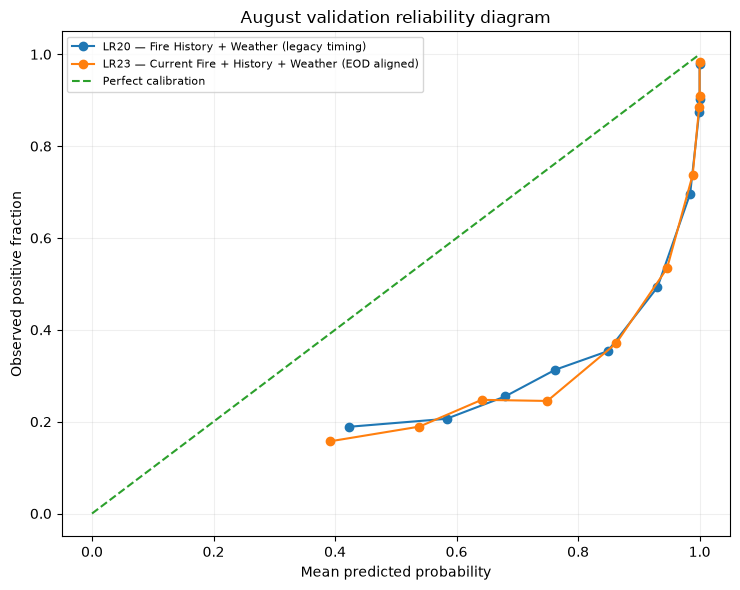

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_baseline_v2_support_only\t2\figures\01_validation_reliability.png


In [15]:
# 14. Reliability diagram for LR20 and LR23
fig, ax = plt.subplots(figsize=(7.5, 6))

for model_name in [
    "LR20 — Fire History + Weather (legacy timing)",
    "LR23 — Current Fire + History + Weather (EOD aligned)",
]:
    score = val_scores[model_name]
    prob_true, prob_pred = calibration_curve(
        val_y,
        score,
        n_bins=10,
        strategy="quantile",
    )
    ax.plot(prob_pred, prob_true, marker="o", label=model_name)

ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed positive fraction")
ax.set_title("August validation reliability diagram")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()

path = FIGURES_DIR / "01_validation_reliability.png"
plt.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", path)

# PART E — Daily August validation behavior

This is the development-stage analogue of the final September rolling backtest. It is safe to inspect August because August is the validation period.

In [16]:
# 15. Daily validation metrics for LR23 (EOD aligned)
focus_name = "LR23 — Current Fire + History + Weather (EOD aligned)"
focus_score = val_scores[focus_name]

val_pred_frame = val[[
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    TARGET,
    "event_type_3d",
    "active_days_prev3_incl_t",
]].copy()
val_pred_frame["pred_probability"] = focus_score
val_pred_frame["pred_05"] = (focus_score >= 0.5).astype(int)

daily_rows = []
for date, day in val_pred_frame.groupby("date"):
    y = day[TARGET].astype(int).to_numpy()
    s = day["pred_probability"].to_numpy()
    p = day["pred_05"].to_numpy()

    daily_rows.append({
        "date": date,
        "rows": len(day),
        "positives": int(y.sum()),
        "positive_rate": float(y.mean()),
        "PR-AUC": average_precision_score(y, s) if y.sum() > 0 else np.nan,
        "Recall@0.5": recall_score(y, p, zero_division=0),
        "Precision@0.5": precision_score(y, p, zero_division=0),
        "F1@0.5": f1_score(y, p, zero_division=0),
    })

daily_validation = pd.DataFrame(daily_rows)
display(daily_validation)

,date,rows,positives,positive_rate,PR-AUC,Recall@0.5,Precision@0.5,F1@0.5
0,2026-08-01,133,35,0.263158,0.723461,0.828571,0.402778,0.542056
1,2026-08-02,133,0,0.000000,NaN,0.000000,0.000000,0.000000
2,2026-08-03,133,23,0.172932,0.611898,0.913043,0.194444,0.320611
3,2026-08-04,133,61,0.458647,0.732201,0.836066,0.520408,0.641509
4,2026-08-05,133,61,0.458647,0.778920,0.950820,0.491525,0.648045
5,2026-08-06,133,60,0.451128,0.848079,0.983333,0.487603,0.651934
6,2026-08-07,133,62,0.466165,0.846871,0.919355,0.491379,0.640449
7,2026-08-08,133,55,0.413534,0.847467,0.963636,0.420635,0.585635
8,2026-08-09,133,77,0.578947,0.851218,0.974026,0.590551,0.735294
9,2026-08-10,133,69,0.518797,0.855186,0.971014,0.531746,0.687179


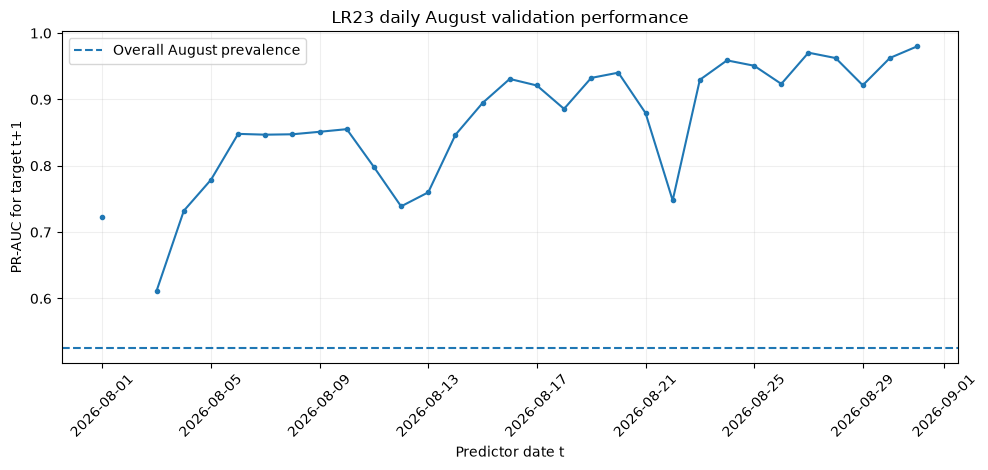

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_baseline_v2_support_only\t2\figures\02_daily_august_pr_auc_lr23.png


In [17]:
# 16. Daily validation PR-AUC plot
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(daily_validation["date"], daily_validation["PR-AUC"], marker="o", markersize=3)
ax.axhline(val_prevalence, linestyle="--", label="Overall August prevalence")
ax.set_xlabel("Predictor date t")
ax.set_ylabel("PR-AUC for target t+1")
ax.set_title("LR23 daily August validation performance")
ax.legend()
ax.grid(alpha=0.2)
plt.xticks(rotation=45)
plt.tight_layout()

path = FIGURES_DIR / "02_daily_august_pr_auc_lr23.png"
plt.savefig(path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", path)

# PART F — Fixed August example: predict Aug 21 from Aug 20

This is deliberately a **validation example**, not the final September test.

The row date is `t = 2026-08-20`; its target is fire activity on `2026-08-21`.

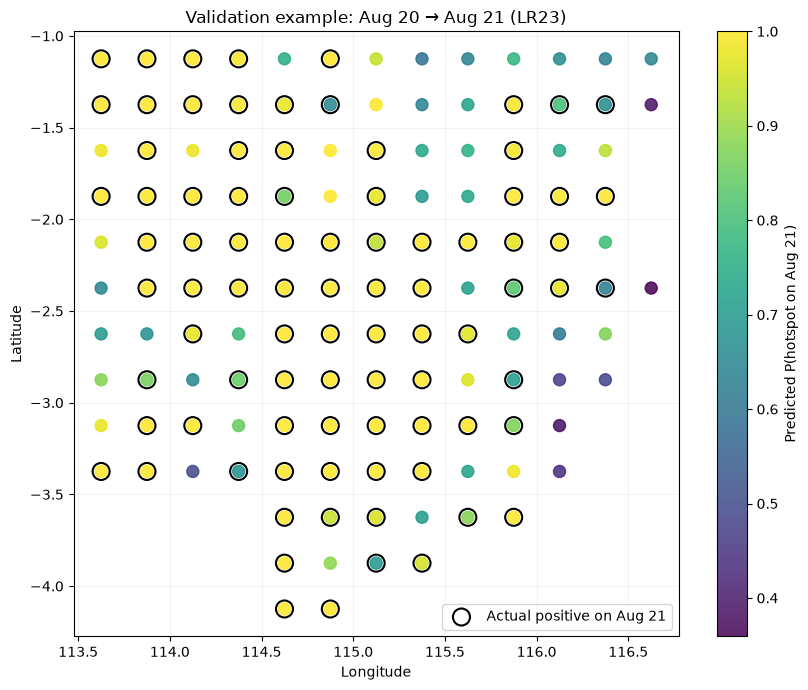

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_baseline_v2_support_only\t2\figures\03_aug20_predict_aug21_lr23.png


In [18]:
# 17. Spatial validation example (Aug 20 -> Aug 21)
EXAMPLE_T = pd.Timestamp("2026-08-20")
example = val_pred_frame[val_pred_frame["date"].eq(EXAMPLE_T)].copy()

if len(example) == 0:
    print("No rows for fixed validation example date:", EXAMPLE_T.date())
else:
    fig, ax = plt.subplots(figsize=(8.5, 7))
    scatter = ax.scatter(
        example["grid_lon"],
        example["grid_lat"],
        c=example["pred_probability"],
        s=75,
        alpha=0.85,
    )

    actual_pos = example[example[TARGET].eq(1)]
    ax.scatter(
        actual_pos["grid_lon"],
        actual_pos["grid_lat"],
        s=150,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        label="Actual positive on Aug 21",
    )

    plt.colorbar(scatter, ax=ax, label="Predicted P(hotspot on Aug 21)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("Validation example: Aug 20 → Aug 21 (LR23)")
    ax.legend()
    ax.grid(alpha=0.15)
    plt.tight_layout()

    path = FIGURES_DIR / "03_aug20_predict_aug21_lr23.png"
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

# PART G — Save validation-only outputs

In [19]:
# 18. Save result tables
reference_table.to_csv(RESULTS_DIR / "reference_baselines.csv", index=False)
lr_results.to_csv(RESULTS_DIR / "lr_validation_results.csv", index=False)
main_comparison.to_csv(RESULTS_DIR / "main_validation_comparison.csv", index=False)
mechanism_deltas.to_csv(RESULTS_DIR / "mechanism_deltas.csv", index=False)
threshold_diagnostic.to_csv(RESULTS_DIR / "validation_threshold_diagnostic.csv", index=False)
subgroup_results.to_csv(RESULTS_DIR / "emerging_persistent_context_results.csv", index=False)
positive_event_recall.to_csv(RESULTS_DIR / "positive_event_recall.csv", index=False)
daily_validation.to_csv(RESULTS_DIR / "daily_august_validation_lr23.csv", index=False)
val_pred_frame.to_csv(RESULTS_DIR / "august_validation_predictions_lr23.csv", index=False)

print("Saved validation-only outputs to:", RESULTS_DIR)

Saved validation-only outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_baseline_v2_support_only\t2


In [20]:
# 19. Save baseline protocol metadata

metadata = {
    "source_notebook": "17_train_only_regional_025_dataset_v2_support_only",
    "locked_region_id": LOCKED_REGION_ID,
    "locked_bbox_wgs84": {
        "west": LOCKED_BBOX[0],
        "south": LOCKED_BBOX[1],
        "east": LOCKED_BBOX[2],
        "north": LOCKED_BBOX[3],
    },
    "nodes": N_NODES,
    "selection_rule": lock_metadata.get("selection_rule"),
    "selection_uses_emerging3": lock_metadata.get("selection_uses_emerging3"),
    "selection_uses_august": lock_metadata.get("selection_uses_august"),
    "selection_uses_september": lock_metadata.get("selection_uses_september"),
    "train_period": [
        str(train["date"].min().date()),
        str(train["date"].max().date()),
    ],
    "validation_period": [
        str(val["date"].min().date()),
        str(val["date"].max().date()),
    ],
    "test_start": str(TEST_START.date()),
    "test_evaluated": False,
    "legacy_timing": {
        "fire": "t-1 or earlier",
        "weather": "day t",
        "target": "t+1",
    },
    "eod_aligned_timing": {
        "current_fire": "day t",
        "fire_history": "t-1 or earlier",
        "weather": "day t",
        "target": "t+1",
    },
    "note": (
        "ERA5 is reanalysis; this is retrospective next-day prediction, "
        "not live operational forecasting."
    ),
    "feature_sets": feature_sets,
}

path = (
    RESULTS_DIR
    / "baseline_protocol_metadata.json"
)

path.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved:", path)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_baseline_v2_support_only\t2\baseline_protocol_metadata.json


# PART H — Automatic interpretation checklist

Do not decide the thesis conclusion from a single metric. Review the following together:

- overall August PR-AUC relative to August prevalence;
- LR10 → LR20 weather delta;
- LR20 → LR23 current-day-fire delta;
- performance relative to persistence;
- Emerging-3 eligible PR-AUC;
- Emerging positive recall;
- calibration / Brier score;
- daily stability across August.

The next notebook should only proceed to spatial-neighbor and wind experiments after this baseline is reviewed.

In [21]:
# 20. Final automatic summary

best_lr_row = (
    lr_results
    .sort_values(
        "PR-AUC",
        ascending=False,
    )
    .iloc[0]
)

emerging_focus = (
    subgroup_results[
        subgroup_results[
            "Context"
        ].str.startswith(
            "Emerging-3 eligible"
        )
    ]
    .sort_values(
        "PR-AUC",
        ascending=False,
    )
)

print("=== Notebook 18 V2 — regional baseline summary ===")
print()

print("DOMAIN")
print("Locked region                :", LOCKED_REGION_ID)
print("BBox                         :", LOCKED_BBOX)
print("Nodes                        :", N_NODES)
print("Selection uses Emerging3     :", lock_metadata.get("selection_uses_emerging3"))
print("Selection uses August        :", lock_metadata.get("selection_uses_august"))
print("Selection uses September     :", lock_metadata.get("selection_uses_september"))
print()

print("SPLIT")
print("Train rows                   :", len(train))
print("Validation rows              :", len(val))
print("Validation positive rate     :", round(val_prevalence, 6))
print("September                    : SEALED")
print()

print("REFERENCE")
print("Persistence PR-AUC           :", round(persistence_metrics["PR-AUC"], 6))
print("Persistence Recall@0.5       :", round(persistence_metrics["Recall"], 6))
print()

print("BEST REGIONAL LR BY PR-AUC")
print("Model                        :", best_lr_row["Model"])
print("PR-AUC                       :", round(float(best_lr_row["PR-AUC"]), 6))
print("Brier                        :", round(float(best_lr_row["Brier"]), 6))
print()

print("MECHANISM DELTAS")
for row in mechanism_deltas.itertuples(index=False):
    comparison = getattr(row, "Comparison")
    delta = getattr(row, "_1")
    print(
        f"{comparison:<45}: "
        f"{delta:+.6f}"
    )

print()
print("EMERGING-3 ELIGIBLE CONTEXT")

display(
    emerging_focus[
        [
            "Model",
            "Rows",
            "Positives",
            "Prevalence",
            "PR-AUC",
            "Recall@0.5",
            "Precision@0.5",
        ]
    ]
)

print()
print(
    "NEXT: review this notebook before Notebook 19 "
    "spatial-neighbor + wind experiments."
)

=== Notebook 18 V2 — regional baseline summary ===

DOMAIN
Locked region                : T2
BBox                         : (113.625, -4.125, 116.625, -1.125)
Nodes                        : 133
Selection uses Emerging3     : False
Selection uses August        : False
Selection uses September     : False

SPLIT
Train rows                   : 11305
Validation rows              : 4123
Validation positive rate     : 0.526073
September                    : SEALED

REFERENCE
Persistence PR-AUC           : 0.715209
Persistence Recall@0.5       : 0.754265

BEST REGIONAL LR BY PR-AUC
Model                        : LR23 — Current Fire + History + Weather (EOD aligned)
PR-AUC                       : 0.876138
Brier                        : 0.261741

MECHANISM DELTAS
Weather gain under legacy timing             : -0.000697
Current-day fire gain beyond legacy LR20     : +0.013090
LR23 vs persistence                          : +0.160929

EMERGING-3 ELIGIBLE CONTEXT


,Model,Rows,Positives,Prevalence,PR-AUC,Recall@0.5,Precision@0.5
2,LR10 — Fire History Only (legacy timing),1241,224,0.1805,0.281965,0.276786,0.397436
4,LR20 — Fire History + Weather (legacy timing),1241,224,0.1805,0.231830,0.839286,0.190669
6,LR23 — Current Fire + History + Weather (EOD a...,1241,224,0.1805,0.229095,0.750000,0.201439
0,Persistence(t),1241,224,0.1805,0.180500,0.000000,0.000000



NEXT: review this notebook before Notebook 19 spatial-neighbor + wind experiments.


# What to send for review

After running Notebook 18 V2 with **Run All**, send:

1. **Section 5** — split table / provenance check
2. **Section 8** — prevalence + persistence
3. **Section 9** — LR validation results
4. **Section 11** — mechanism deltas
5. **Section 12** — Emerging/Persistent context table
6. **Section 13** — positive-event recall
7. **Section 20** — final automatic summary

If available, also send the reliability diagram.

Do **not** inspect September yet.